In [23]:

import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from set_style import set_style
from matplotlib.patches import Circle
import re


h = 0.678


## Fig. 1 for draft 

Mhalo, cold gas mass and SFR evolution for 4 models. Also, a redshift zoom with observational data compiled.



In [27]:
# for Mhalo

with h5py.File('HaloID_track_Gizmo7k.hdf5','r') as f:
    z = f['z'][()]
cosmo = FlatLambdaCDM(H0=67.8, Om0=0.31)
lookback_time_halo = cosmo.lookback_time(z).value

with h5py.File('Historic_data_324.hdf5','r') as f:
    keys = list(f.keys())

keys_halo = [k for k in keys if k.startswith('cluster')]

# For Mgas and SFR
with h5py.File('Mgas_sfr_complete_comovil.hdf5','r') as f:
    keys = list(f.keys())
    lbk_time, z = f['lookback_time'][()], f['z'][()]
keys_c = [k for k in keys if k.startswith('cluster')]

#lbk_time, z = f['lookback_time'][()], f['z'][()]

mass_conv = 1e10/h

In [28]:

# ---------------------------------------------------------------------------
# Observational z~4-5 protocluster cores, to overplot on the Mcold / SFR panels.
# Add after the simulation curves are drawn (needs a1, a2 and the sim arrays z, t).
# Lookback times are interpolated from the simulation's own t(z), so the
# kind: "val" (value +/- err), "lo" (lower limit), "up" (upper limit)
# ---------------------------------------------------------------------------

# Halo masses [Msun] -- not plotted (no sim Mhalo in this file), same format as above
OBS_MHALO = [
    ("DRC (Oteo+18)",          4.002, 4.4e13, 0, 0, "val"),
    # sigma_v range: 3.2e13 (uniform sphere) to 9.3e13 (Evrard+08); plotted at geometric mean
    ("DRC (Oteo+18)",       4.002, 5.45e13, 2.25e13, 3.85e13, "val"),
    ("DRC (Long+20)",                4.002, 5.0e13, 2.0e13, 2.0e13, "val"),
    ("SPT2349-56 (Miller+18)",       4.304, 1.16e13, 0.70e13, 0.70e13, "val"),  # upper limit if not virialized
    ("SPT2349-56 (Hill+20, Zhou+25)",   4.304, 9.0e12, 5.0e12, 5.0e12, "val"),
    ("J0053 (Hedge+25)",     3.879, 3.0e13, 0, 0, "val"),               # simulation analogue, not measured
    ("AzTEC-3 (Riechers+10, Capak+11)",           5.300, 4.0e11, 0, 0, "lo"),
]

OBS_MCOLD = [
    # label, z, value [Msun], err_lo, err_hi, kind
    ("DRC (Oteo+18)",          4.002, 6.6e11, 0, 0, "lo"),
    ("DRC (Long+20)",          4.002, 1.8e12, 0.45e12, 0.45e12, "val"),
    ("SPT2349-56 (Miller+18)",   4.304, 6.7e11, 0.5e11, 0.5e11, "val"),
    ("SPT2349-56 (Hill+20, Zhou+25)", 4.304, 1.855e12, 0.182e12, 0.182e12, "lo"),
    ("J0053 (Hedge+25)",         3.879, 5.5e10, 0, 0, "lo"),
    ("AzTEC-3 (Riechers+10, Capak+11)",    5.300, 5.3e10, 0, 0, "lo"),
]
OBS_SFR = [
    ("DRC (Oteo+18)",                4.002, 6500., 0, 0, "lo"),
    ("DRC (Long+20)",                4.002, 5973., 0, 0, "val"),
    ("SPT2349-56 (Miller+18)",       4.304, 6000., 600., 600., "val"),
    ("J0053 (Hedge+25)",             3.879, 2000., 0, 0, "up"),
    ("AzTEC-3 (Riechers+10, Capak+11)", 5.300, 1600., 500., 500., "val"),
]

 
STYLE = {  # one colour/marker per object, filled = fiducial, open = alternative estimate
    "DRC":        dict(c="#1b9e77", m="s"),
    "SPT2349-56": dict(c="#d95f02", m="D"),
    "J0053":      dict(c="#7570b3", m="^"),
    "AzTEC-3":    dict(c="#e7298a", m="o"),
}
 
def _style(label):
    for k, s in STYLE.items():
        if label.startswith(k):
            return s
    return dict(c="k", m="o")
 
def add_obs(ax, obs, z_sim, t_sim, arrow_dex=0.25):
    o = np.argsort(z_sim)
    seen = {}
    for lab, zo, v, elo, ehi, kind in obs:
        s = _style(lab)
        key = lab.split(" (")[0]
        n = seen.get(key, 0); seen[key] = n + 1
        to = np.interp(zo, z_sim[o], t_sim[o]) + 0.03 * n     # small offset if same object twice
        arrow = v * (10**arrow_dex - 1)
        kw = dict(fmt=s["m"], color=s["c"], ms=7, mec="k", mew=0.6, capsize=3,
                  elinewidth=1.2, label=lab, zorder=5,
                  mfc=s["c"] if n == 0 else "white")
        if kind == "val":
            ax.errorbar(to, v, yerr=[[elo], [ehi]] if (elo or ehi) else None, **kw)
        elif kind == "lo":
            ax.errorbar(to, v, yerr=[[0], [arrow]], lolims=True, **kw)
            if elo:  # also show the measurement error
                ax.errorbar(to, v, yerr=[[elo], [ehi]], fmt="none", color=s["c"], capsize=3, zorder=5)
        elif kind == "up":
            ax.errorbar(to, v, yerr=[[v * (1 - 10**-arrow_dex)], [0]], uplims=True, **kw)

    return 0
    

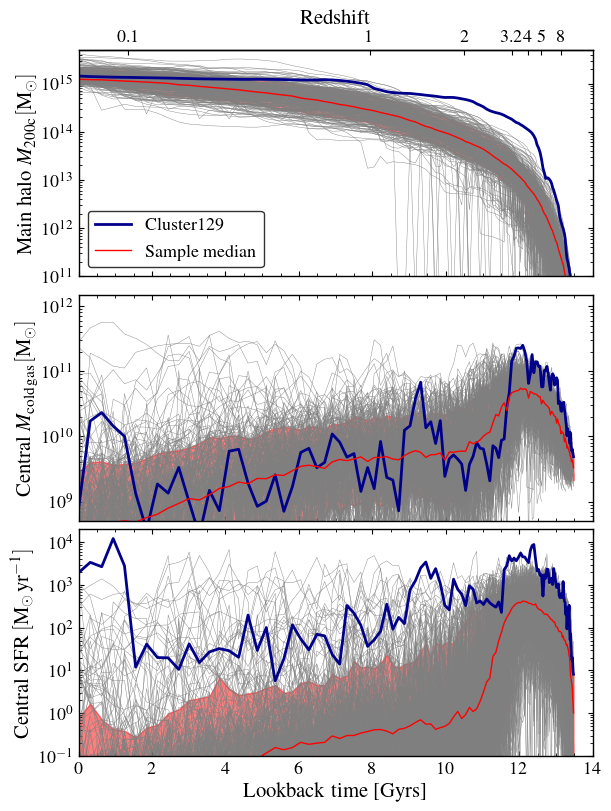

In [34]:


fname_halo = 'Historic_data_324.hdf5'
fname_gas = 'Mgas_sfr_complete_comovil.hdf5'

set_style('mnras')
fs = 15
fig, ax = plt.subplots(3,1, figsize=(6,8), sharex=True)
ax = ax.flatten()

#fig.suptitle('Gizmo 7k', fontsize=fs+2)

ax[2].set_xlabel('Lookback time [Gyrs]', fontsize=fs)
#ax.set_ylabel(r'$f_{\rm edd}=\dot{M}_{\rm BH}/\dot{M}_{\rm edd}$', fontsize=fs)
ax[0].set_ylabel(r'Main halo $ M_{\rm 200c} \, [{\rm M_\odot}]$', fontsize=fs)
ax[1].set_ylabel(r'Central $M_{\rm cold\, gas} \, [{\rm M_\odot}]$', fontsize=fs)
ax[2].set_ylabel(r'Central SFR $[{\rm M_\odot\, yr^{-1}}]$', fontsize=fs)

for i in range(3):
    ax[i].set_yscale('log')
    ax[i].tick_params(labelsize=fs-2)

ax[0].set_xlim([0,14])

ax[0].set_ylim([1e11,5e15])
ax[1].set_ylim([5e8,1.5e12])
ax[2].set_ylim([1e-1,2e4])

# HALO MASS EVOLUTION 

mhalo_all = np.zeros((324,129))
mgas_all = np.zeros((324,126))
sfr_all = np.zeros((324,126))

for i, key in enumerate(keys_halo):
    with h5py.File(fname_halo,'r') as f1:
        mhalo = f1[f'{key}/M200c'][()]/h
        ax[0].plot(lookback_time_halo, mhalo, lw=0.3, color='gray')
        mhalo_all[i] = mhalo

# COLD GAS AND SFR
for i,key in enumerate(keys_c):

    with h5py.File(fname_gas,'r') as f:
        mgas = f[f'{key}/Mcoldgas'][()]
        mgas[mgas==0] = 1e7
        ax[1].plot(lbk_time, mgas, lw=0.3, color='gray')

        sfr = f[f'{key}/SFR'][()]
        sfr[sfr==0] = 1e-2
        ax[2].plot(lbk_time, sfr, lw=0.3, color='gray')

        mgas_all[i] = mgas
        sfr_all[i] = sfr

mhalo_10, mhalo_med, mhalo_90 = np.nanpercentile(mhalo_all, [10,50,90], axis=0)
mgas_10, mgas_med, mgas_90 = np.nanpercentile(mgas_all, [10,50,90], axis=0)
sfr_10, sfr_med, sfr_90 = np.nanpercentile(sfr_all, [10,50,90], axis=0)


# Cluster 129
with h5py.File(fname_halo,'r') as f1:
    mhalo = f1[f'cluster_0129/M200c'][()]/h
    ax[0].plot(lookback_time_halo, mhalo, lw=2, color='darkblue', label='Cluster129')


with h5py.File(fname_gas,'r') as f:
    mgas = f[f'cluster_0129/Mcoldgas'][()]
    ax[1].plot(lbk_time, mgas, lw=2, color='darkblue')
    
    sfr = f[f'cluster_0129/SFR'][()]
    sfr[sfr==0] = 1e-2
    ax[2].plot(lbk_time, sfr, lw=2, color='darkblue')

# MEDIAN AND PERCENTILES
ax[0].plot(lookback_time_halo, mhalo_med, lw=1, color='red', label='Sample median')
ax[0].fill_between(lookback_time_halo, mhalo_10, mhalo_90, color='red', alpha=0.5)

ax[1].plot(lbk_time, mgas_med, lw=1, color='red')
ax[1].fill_between(lbk_time, mgas_10, mgas_90, color='red', alpha=0.5)

ax[2].plot(lbk_time, sfr_med, lw=1, color='red')
ax[2].fill_between(lbk_time, sfr_10, sfr_90, color='red', alpha=0.5)

#for i in range(3): 
 #   for isnap in [128-46, 128-55,128-63]:
  #      ax[i].axvline(lookback_time_halo[isnap], 0,1,ls='--',lw=0.5, color='gray') # z=5.15,4,3.22

        
#add_obs(ax[0], OBS_MHALO, z, lbk_time)
#add_obs(ax[1], OBS_MCOLD, z, lbk_time)
#add_obs(ax[2], OBS_SFR, z, lbk_time)

# twin ax

zt   = np.array([0.1, 1, 2, 3.22, 4, 5, 8])
t_zt = cosmo.lookback_time(zt).value 

ax[0].tick_params(axis="x", which="both", top=False, )
sec = ax[0].secondary_xaxis("top")
sec.set_xticks(t_zt)
sec.set_xticklabels(["0.1", "1", "2", "3.2", "4", "5", "8"])
sec.minorticks_off()
sec.set_xlabel("Redshift", fontsize=fs)
sec.tick_params(axis="x", which="both", labelsize=fs-2)

ax[0].legend(loc='lower left', fontsize=fs-2)
#ax[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )
#ax[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )
#ax[2].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )


plt.savefig('3panels_evolution_all_gizmo7k.png', dpi=400)
plt.show()


## Two panels for Gizmo3k, GadgetX, SAG

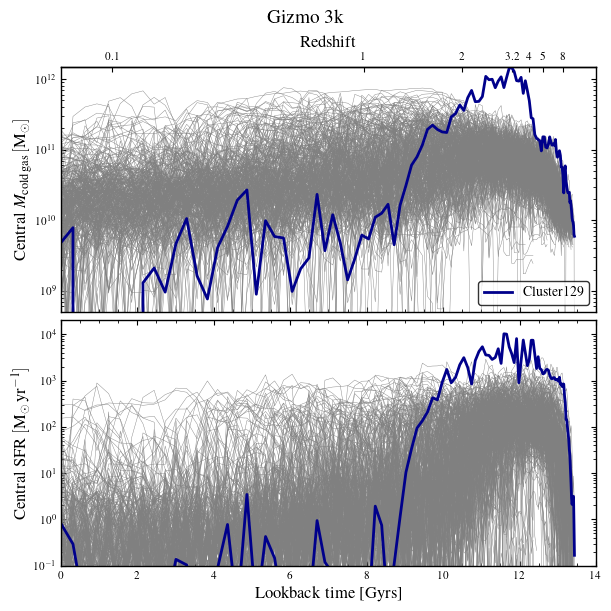

In [241]:

fname_gas = 'Mgas_sfr_complete_gizmo3k_comovil.hdf5'

set_style('mnras', Hratio=0.75)
fs = 12
fig, ax = plt.subplots(2,1, figsize=(6,6), sharex=True)
ax = ax.flatten()

fig.suptitle('Gizmo 3k', fontsize=fs+2)

ax[1].set_xlabel('Lookback time [Gyrs]', fontsize=fs)

ax[0].set_ylabel(r'Central $M_{\rm cold\, gas} \, [{\rm M_\odot}]$', fontsize=fs)
ax[1].set_ylabel(r'Central SFR $[{\rm M_\odot\, yr^{-1}}]$', fontsize=fs)

for axes in ax:
    axes.set_yscale('log')

ax[0].set_xlim([0,14])

ax[0].set_ylim([5e8,1.5e12])
ax[1].set_ylim([1e-1,2e4])


# COLD GAS AND SFR
for key in keys_c:

    with h5py.File(fname_gas,'r') as f:
        mgas = f[f'{key}/Mcoldgas'][()]
        mgas[mgas==0] = 1e7
        ax[0].plot(lbk_time, mgas, lw=0.3, color='gray')

        sfr = f[f'{key}/SFR'][()]
        sfr[sfr==0] = 1e-2
        ax[1].plot(lbk_time, sfr, lw=0.3, color='gray')

# Cluster 129
with h5py.File(fname_gas,'r') as f:
    mgas = f[f'cluster_0129/Mcoldgas'][()]
    ax[0].plot(lbk_time, mgas, lw=2, color='darkblue', label='Cluster129')
    sfr = f[f'cluster_0129/SFR'][()]
    sfr[sfr==0] = 1e-2

    ax[1].plot(lbk_time, sfr, lw=2, color='darkblue')



#for i in range(3): 
 #   for isnap in [128-46, 128-55,128-63]:
  #      ax[i].axvline(lookback_time_halo[isnap], 0,1,ls='--',lw=0.5, color='gray') # z=5.15,4,3.22

        
#add_obs(ax[0], OBS_MHALO, z, lbk_time)
#add_obs(ax[1], OBS_MCOLD, z, lbk_time)
#add_obs(ax[2], OBS_SFR, z, lbk_time)

# twin ax

zt   = np.array([0.1, 1, 2, 3.22, 4, 5, 8])
t_zt = cosmo.lookback_time(zt).value 

ax[0].tick_params(axis="x", which="both", top=False)
sec = ax[0].secondary_xaxis("top")
sec.set_xticks(t_zt)
sec.set_xticklabels(["0.1", "1", "2", "3.2", "4", "5", "8"])
sec.minorticks_off()
sec.set_xlabel("Redshift", fontsize=fs)


ax[0].legend(loc='lower right', fontsize=fs-2)
#ax[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )
#ax[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )
#ax[2].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )


plt.savefig('2panels_evolution_all_gizmo3k.png', dpi=400)
plt.show()


# GADGET-X

In [250]:
with h5py.File('Mgas_sfr_complete_gadgetx_comovil.hdf5','r') as f:
    keys = list(f.keys())
    lbk_time, z = f['lookback_time'][()], f['z'][()]
keys_g = [k for k in keys if k.startswith('cluster')]

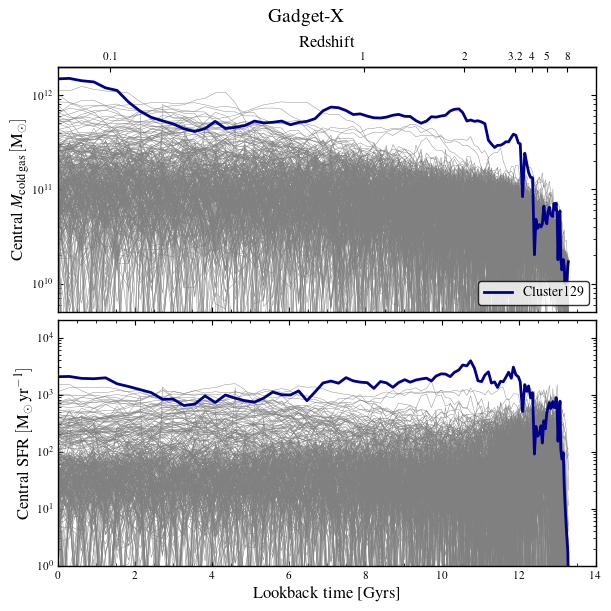

In [253]:

fname_gas = 'Mgas_sfr_complete_gadgetx_comovil.hdf5'

set_style('mnras', Hratio=0.75)
fs = 12
fig, ax = plt.subplots(2,1, figsize=(6,6), sharex=True)
ax = ax.flatten()

fig.suptitle('Gadget-X', fontsize=fs+2)

ax[1].set_xlabel('Lookback time [Gyrs]', fontsize=fs)

ax[0].set_ylabel(r'Central $M_{\rm cold\, gas} \, [{\rm M_\odot}]$', fontsize=fs)
ax[1].set_ylabel(r'Central SFR $[{\rm M_\odot\, yr^{-1}}]$', fontsize=fs)

for axes in ax:
    axes.set_yscale('log')

ax[0].set_xlim([0,14])

ax[0].set_ylim([5e9,2e12])
ax[1].set_ylim([1e0,2e4])


# COLD GAS AND SFR
for key in keys_g:

    with h5py.File(fname_gas,'r') as f:
        mgas = f[f'{key}/Mcoldgas'][()]
        mgas[mgas==0] = 1e7
        ax[0].plot(lbk_time, mgas, lw=0.3, color='gray')

        sfr = f[f'{key}/SFR'][()]
        sfr[sfr==0] = 1e-2
        ax[1].plot(lbk_time, sfr, lw=0.3, color='gray')

# Cluster 129
with h5py.File(fname_gas,'r') as f:
    mgas = f[f'cluster_0129/Mcoldgas'][()]
    ax[0].plot(lbk_time, mgas, lw=2, color='darkblue', label='Cluster129')
    sfr = f[f'cluster_0129/SFR'][()]
    sfr[sfr==0] = 1e-2

    ax[1].plot(lbk_time, sfr, lw=2, color='darkblue')



#for i in range(3): 
 #   for isnap in [128-46, 128-55,128-63]:
  #      ax[i].axvline(lookback_time_halo[isnap], 0,1,ls='--',lw=0.5, color='gray') # z=5.15,4,3.22

        
#add_obs(ax[0], OBS_MHALO, z, lbk_time)
#add_obs(ax[1], OBS_MCOLD, z, lbk_time)
#add_obs(ax[2], OBS_SFR, z, lbk_time)

# twin ax

zt   = np.array([0.1, 1, 2, 3.22, 4, 5, 8])
t_zt = cosmo.lookback_time(zt).value 

ax[0].tick_params(axis="x", which="both", top=False)
sec = ax[0].secondary_xaxis("top")
sec.set_xticks(t_zt)
sec.set_xticklabels(["0.1", "1", "2", "3.2", "4", "5", "8"])
sec.minorticks_off()
sec.set_xlabel("Redshift", fontsize=fs)


ax[0].legend(loc='lower right', fontsize=fs-2)
#ax[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )
#ax[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )
#ax[2].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs-2 )


plt.savefig('plots/2panels_evolution_all_gadget.png', dpi=400)
plt.show()


# SAG semi-analytic model. 

There are 153 available regions with SAG data at 3k resolution. 

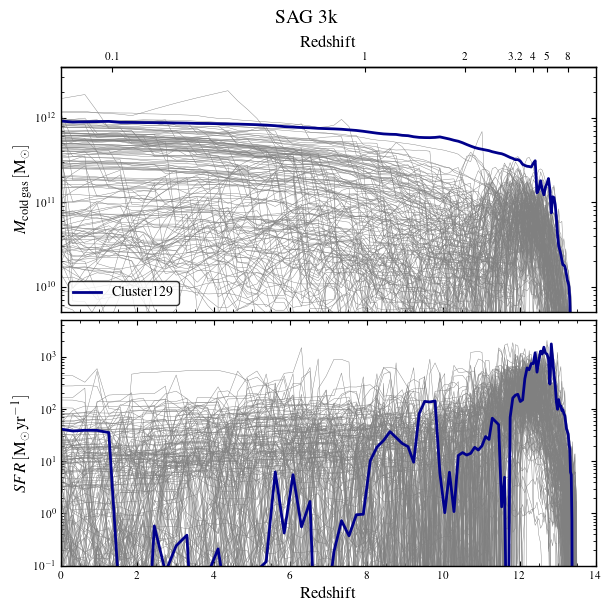

In [254]:
path = '/data3/users/tomas/SAG300/SalidaSAM/'

clusters = np.sort([
    1, 21, 41, 77, 119, 189, 232, 282,
    2, 22, 42, 80, 120, 194, 233, 285,
    3, 23, 43, 81, 127, 195, 234, 290,
    4, 24, 45, 82, 128, 202, 237, 293,
    5, 25, 47, 84, 129, 205, 242, 295,
    6, 26, 49, 85, 135, 206, 245, 299,
    7, 27, 52, 86, 141, 207, 246, 300,
    8, 28, 54, 90, 142, 212, 247, 301,
    9, 57, 91, 145, 213, 248, 306,
    10, 30, 58, 93, 146, 214, 249, 314,
    11, 31, 59, 94, 153, 216, 251, 317,
    12, 32, 61, 95, 155, 217, 253, 319,
    13, 33, 62, 96, 159, 219, 254, 320,
    14, 34, 63, 98, 163, 221, 259, 324,
    15, 35, 64, 99, 165, 223, 260, 
    16, 36, 65, 102, 178, 225, 266,
    17, 37, 67, 107, 179, 226, 268,
    18, 38, 69, 108, 181, 227, 271,
    19, 39, 74, 114, 184, 230, 274,
    20, 40, 75, 117, 187, 231, 276
])

h = 0.678

z = np.genfromtxt('/data3/users/tomas/Sussing100Mpc/100Mpc_384_dmonly_Sussing/snapidzred-300.txt', usecols=[2], skip_header=1)
cosmo = FlatLambdaCDM(H0=67.8, Om0=0.3)
lookback_time = cosmo.lookback_time(z).value

fig, _axes = plt.subplots(2,1, figsize=(6,6), sharex=True)

fig.suptitle('SAG 3k',fontsize=fs+2)
axes = _axes.flatten()

for ax in axes:
    #ax.set_xlabel(r'Lookback time [Gyrs]', fontsize=fs) 
    ax.set_yscale('log')
    ax.set_xlim([0,14])
    

axes[0].set_ylabel(r'$M_{\rm cold\,gas} \, [{\rm M_\odot}]$', fontsize=fs)
axes[1].set_ylabel(r'$SFR \, [{\rm M_\odot\, yr^{-1}}]$', fontsize=fs)
axes[1].set_xlabel(r'Redshift', fontsize=fs) 


axes[0].set_ylim([5e9,4e12])
axes[1].set_ylim([1e-1,5e3])

for ic in clusters:
    fname = path+f'NewMDCLUSTER_{ic:04d}/gal_128_SAG-7.130-Tom300.hdf5'
    with h5py.File(fname, 'r') as f:
        SFR = f['Histories/SFRprog'][0,:]
        Mhalo = f['Histories/M200cT'][0,:]/h
        Mstar = f['Histories/StellarMass'][0,:]/h
        Mcold = f['Histories/ColdGas'][0,:]/h
        Mhalo[Mhalo==0] = 1e10
        SFR[SFR==0] = 1e-4

        axes[0].plot(lookback_time, Mcold, lw=0.31, color='gray')
        axes[1].plot(lookback_time, SFR, lw=0.3, color='gray')


ic = 129
fname = path+f'NewMDCLUSTER_{ic:04d}/gal_128_SAG-7.130-Tom300.hdf5'
with h5py.File(fname, 'r') as f:
    Mhalo = f['Histories/M200cT'][0,:]/h
    Mhalo[Mhalo==0] = 1e10
    Mstar = f['Histories/StellarMass'][0,:]/h
    Mcold = f['Histories/ColdGas'][0,:]/h
    SFR = f['Histories/SFRprog'][0,:]
    SFR[SFR==0] = 1e-4
    
axes[0].plot(lookback_time, Mcold, lw=2, color='darkblue', label='Cluster129')
axes[1].plot(lookback_time, SFR, lw=2, color='darkblue')

# twin ax

zt   = np.array([0.1, 1, 2, 3.22, 4, 5, 8])
t_zt = cosmo.lookback_time(zt).value 

axes[0].tick_params(axis="x", which="both", top=False)
sec = axes[0].secondary_xaxis("top")
sec.set_xticks(t_zt)
sec.set_xticklabels(["0.1", "1", "2", "3.2", "4", "5", "8"])
sec.minorticks_off()
sec.set_xlabel("Redshift", fontsize=fs)

axes[0].legend(loc='lower left', fontsize=fs-2)

plt.savefig('plots/2panels_evolution_all_sag.png', dpi=200)


# Fig 1 of paper. 3 panels.

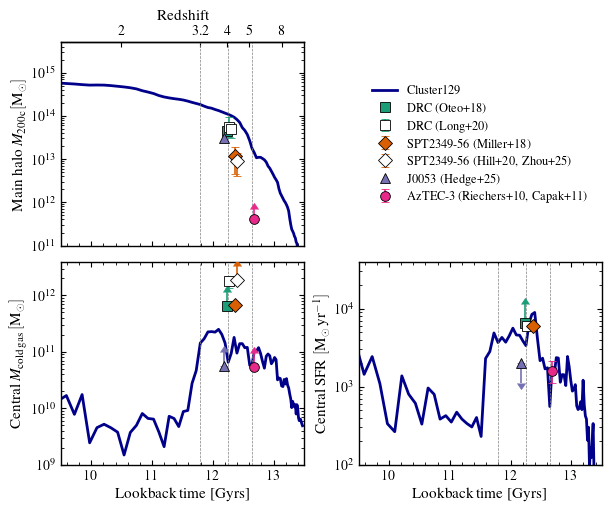

In [12]:


set_style('mnras', Hratio=0.75)
fs = 11
fig, axs = plt.subplots(2,2, figsize=(6,5), sharex=True )
ax_halo, lax = axs[0, 0], axs[0, 1]     # lax = legend panel
ax_gas,  ax_sfr = axs[1, 0], axs[1, 1]
ax = [ax_halo, ax_gas, ax_sfr]  
#ax = ax.flatten()


ax[1].set_xlabel('Lookback time [Gyrs]', fontsize=fs)
ax[2].set_xlabel('Lookback time [Gyrs]', fontsize=fs)
#ax.set_ylabel(r'$f_{\rm edd}=\dot{M}_{\rm BH}/\dot{M}_{\rm edd}$', fontsize=fs)
ax[0].set_ylabel(r'Main halo $ M_{\rm 200c} \, [{\rm M_\odot}]$', fontsize=fs)
ax[1].set_ylabel(r'Central $M_{\rm cold\, gas} \, [{\rm M_\odot}]$', fontsize=fs)
ax[2].set_ylabel(r'Central SFR $[{\rm M_\odot\, yr^{-1}}]$', fontsize=fs)

for i in range(3):
    ax[i].set_yscale('log')
    ax[i].tick_params(labelsize=fs-1)

ax[0].set_xlim([9.5,13.5])

ax[0].set_ylim([1e11,5e15])
ax[1].set_ylim([1e9,4e12])
ax[2].set_ylim([1e2,4e4])

# HALO MASS EVOLUTION 


# Cluster 129
with h5py.File('Historic_data_324.hdf5','r') as f1:
    mhalo = f1[f'cluster_0129/M200c'][()]
    ax[0].plot(lookback_time_halo, mhalo/h, lw=2, color='darkblue', label='Cluster129')
    
with h5py.File('Mgas_sfr_complete_comovil.hdf5','r') as f1:
    lbk_time, z = f1['lookback_time'][()], f1['z'][()]
    mgas = f1[f'cluster_0129/Mcoldgas'][()]
    ax[1].plot(lbk_time, mgas, lw=2, color='darkblue')
    sfr = f1[f'cluster_0129/SFR'][()]
    ax[2].plot(lbk_time, sfr, lw=2, color='darkblue')


for i in range(3): 
    for isnap in [128-46, 128-55,128-63]:
        ax[i].axvline(lookback_time_halo[isnap], 0,1,ls='--',lw=0.5, color='gray') # z=5.15,4,3.22
    

add_obs(ax[0], OBS_MHALO, z, lbk_time)
add_obs(ax[1], OBS_MCOLD, z, lbk_time)
add_obs(ax[2], OBS_SFR, z, lbk_time)

# twin ax
zgrid = np.linspace(0, 20, 2000)
tgrid = cosmo.lookback_time(zgrid).value
t2z = lambda tl: np.interp(tl, tgrid, zgrid)
z2t = lambda z: np.interp(z, zgrid, tgrid)

ax[0].tick_params(axis="x", which="both", top=False)
sec = ax[0].secondary_xaxis("top", functions=(t2z, z2t))
sec.set_xticks([2, 3.22, 4, 5, 8])
sec.set_xticklabels(["2", "3.2", "4", "5", "8"])
sec.minorticks_off()
sec.set_xlabel("Redshift", fontsize=fs)
sec.tick_params(labelsize=fs-1)

#ax[0].legend(loc='best', fontsize=fs-2)

# ---- shared legend in the empty upper-right panel ----
def ref_label(lab):
    """'DRC (Oteo+18, [CI])' -> 'DRC (Oteo+18)'"""
    m = re.match(r'(.+?) \(([^,)]+)', lab)
    #return f"{m.group(1)} ({m.group(2)})" if m else lab
    return lab

handles, labels = {}, []
for a in ax:
    for hnd, lab in zip(*a.get_legend_handles_labels()):
        key = ref_label(lab)
        if key not in handles:          # first occurrence wins
            handles[key] = hnd
            labels.append(key)

lax.axis('off')
lax.legend([handles[k] for k in labels], labels, loc='center',
           frameon=False, fontsize=fs-2)



plt.savefig('3panels_evolution129_obs.png', dpi=400)
plt.show()
